# Overlaying speed traces of two laps

Compare two fastest laps by overlaying their speed traces.


In [2]:
import matplotlib.pyplot as plt

import fastf1.plotting


# Enable Matplotlib patches for plotting timedelta values and load
# FastF1's dark color scheme
fastf1.plotting.setup_mpl(mpl_timedelta_support=True, misc_mpl_mods=False,
                          color_scheme='fastf1')

# load a session and its telemetry data
session = fastf1.get_session(2025, 'CANADA', 'Q')
session.load()

core           INFO 	Loading data for Canadian Grand Prix - Qualifying [v3.5.3]
req            INFO 	No cached data found for session_info. Loading data...
_api           INFO 	Fetching session info data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for driver_info. Loading data...
_api           INFO 	Fetching driver list...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for session_status_data. Loading data...
_api           INFO 	Fetching session status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for track_status_data. Loading data...
_api           INFO 	Fetching track status data...
req            INFO 	Data has been written to cache!
req            INFO 	No cached data found for _extended_timing_data. Loading data...
_api           INFO 	Fetching timing data...
_api           INFO 	Parsing timing data...
req            INFO

First, we select the two laps that we want to compare



In [10]:
col_lap = session.laps.pick_drivers('COL').pick_fastest()
gas_lap = session.laps.pick_drivers('GAS').pick_fastest()

Next we get the telemetry data for each lap. We also add a 'Distance' column
to the telemetry dataframe as this makes it easier to compare the laps.



In [11]:
col_tel = col_lap.get_car_data().add_distance()
gas_tel = gas_lap.get_car_data().add_distance()

Finally, we create a plot and plot both speed traces.
We color the individual lines with the driver's team colors.



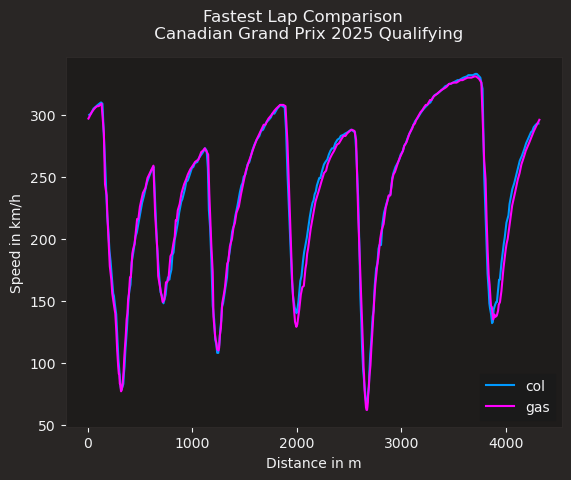

In [17]:
col_color = '#0099ff'
gas_color = '#ff00ff'

fig, ax = plt.subplots()
ax.plot(col_tel['Distance'], col_tel['Speed'], color=col_color, label='col')
ax.plot(gas_tel['Distance'], gas_tel['Speed'], color=gas_color, label='gas')

ax.set_xlabel('Distance in m')
ax.set_ylabel('Speed in km/h')

ax.legend()
plt.suptitle(f"Fastest Lap Comparison \n "
             f"{session.event['EventName']} {session.event.year} Qualifying")

plt.show()